In [6]:
#chargement
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path("../data")
df = pd.read_csv(DATA_DIR / "raw" / "chanel_with_paths.csv")
print(df.shape)
print("Images disponibles :", df["image_ok"].sum())

(1428, 19)
Images disponibles : 918


In [7]:
#colonnes constantes et vals manquantes
for c in ["website_name", "country_code", "currency_code", "brand"]:
    print(c, df[c].unique())

print("\nDates :", df["competence_date"].unique())
print("\nValeurs manquantes :")
print(df.isna().sum()[df.isna().sum() > 0])

website_name <ArrowStringArray>
['Chanel']
Length: 1, dtype: str
country_code <ArrowStringArray>
['DEU']
Length: 1, dtype: str
currency_code <ArrowStringArray>
['EUR']
Length: 1, dtype: str
brand <ArrowStringArray>
['CHANEL']
Length: 1, dtype: str

Dates : <ArrowStringArray>
['2023-11-17']
Length: 1, dtype: str

Valeurs manquantes :
Series([], dtype: int64)


In [8]:
#les 3 niveaux de catégories
pd.set_option("display.max_rows", None)
for c in ["category1_code", "category2_code", "category3_code"]:
    print(f"\n--- {c} : {df[c].nunique()} classes ---")
    print(df[c].value_counts(dropna=False))


--- category1_code : 7 classes ---
category1_code
FASHION      550
FRAGRANCE    199
JEWELRY      193
EYEWEAR      163
MAKEUP       121
SKINCARE     104
WATCHES       98
Name: count, dtype: int64

--- category2_code : 51 classes ---
category2_code
READY-TO-WEAR                  243
COSTUME JEWELRY                127
SUNGLASSES                      99
WOMEN                           88
WATCHES                         87
MEN                             72
HANDBAGS                        61
COCO CRUSH                      54
SHOES                           42
FACE                            41
EYEGLASSES                      40
SMALL LEATHER GOODS             38
BATH AND BODY                   36
RINGS                           35
EYES                            35
MOISTURIZERS                    35
NECKLACES                       30
EARRINGS                        26
BRUSHES AND ACCESSORIES         26
BLUE LIGHT GLASSES              24
LIPS                            21
N°5              

count      1428.000000
mean       6076.253725
std       15219.005999
min          23.000000
25%         195.000000
50%        1415.000000
75%        5800.000000
max      142000.000000
Name: price_eur, dtype: float64


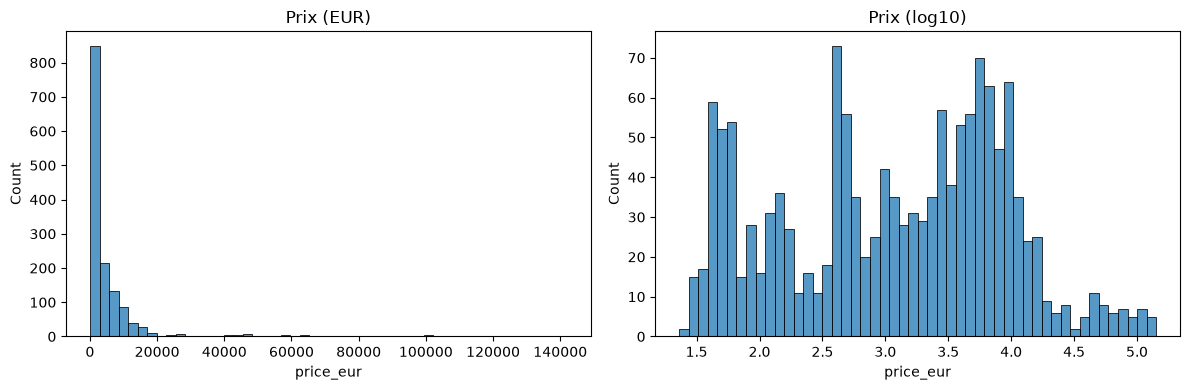

In [9]:
#prix
print(df["price_eur"].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price_eur"], bins=50, ax=ax[0])
ax[0].set_title("Prix (EUR)")
sns.histplot(np.log10(df["price_eur"].dropna()), bins=50, ax=ax[1])
ax[1].set_title("Prix (log10)")
plt.tight_layout()
plt.show()

In [10]:
#longueur des titres
df["title_len_words"] = df["title"].fillna("").str.split().str.len()
df["title_len_chars"] = df["title"].fillna("").str.len()
print(df[["title_len_words", "title_len_chars"]].describe())

print("\nTitres courts :", df.nsmallest(5, "title_len_chars")["title"].tolist())
print("\nExemples :")
print(df["title"].sample(15, random_state=0).to_string())
print("\nTitres vides ou 'n.a.' :", (df["title"].isna() | df["title"].str.lower().eq("n.a.")).sum())

       title_len_words  title_len_chars
count      1428.000000      1428.000000
mean          5.094538        39.056022
std           2.519752        20.365571
min           1.000000         4.000000
25%           3.000000        26.000000
50%           5.000000        36.000000
75%           7.000000        51.000000
max          19.000000       162.000000

Titres courts : ['n.a.', 'Blau', 'n.a.', 'n.a.', 'n.a.']

Exemples :
459                        Steppmotiv  18 Karat BEIGEGOLD
822                             18 Karat Rotgold  Diamant
445                          18 Karat Weißgold  Diamanten
911               Metall & Glasperlen  Goldfarben & Braun
530     Metall  Strass & Glasperlen  Silberfarben  Kri...
540                Lammfell & silberfarbenes Metall  Weiß
1146       Dunkles Schildpatt. Gläser: Braun  Mit Verlauf
326                      Bedruckter Denim  Schwarz & Weiß
231                          Samt  Schwarz & silberfarben
1127      Schwarz. Gläser: Grau  Polarisiert  Mi

### Qualité et diversité des images

##### Les images on été toutes converties en format JPEG et RGB, donc le format qu'on va afficher est celui de nos fichiers, et pas celui d'origine

In [11]:
#dimensions et format
from PIL import Image

df_img = df[df["image_ok"]].copy()

def get_info(p):
    with Image.open(p) as im:
        return im.width, im.height, im.mode

info = df_img["image_path"].apply(get_info)
df_img["width"] = info.apply(lambda x: x[0])
df_img["height"] = info.apply(lambda x: x[1])
df_img["mode"] = info.apply(lambda x: x[2])
df_img["ratio"] = df_img["width"] / df_img["height"]

print(df_img[["width", "height", "ratio"]].describe())
print("\nDimensions les plus fréquentes :")
print(df_img.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))
print("\nModes couleur :", df_img["mode"].value_counts().to_dict())

            width       height       ratio
count  918.000000   918.000000  918.000000
mean   316.358388   367.966231    0.885283
std    116.802824    95.572818    0.372090
min     20.000000    41.000000    0.058480
25%    228.000000   351.000000    0.775473
50%    378.000000   400.000000    0.945000
75%    378.000000   400.000000    0.972500
max    682.000000  1004.000000    3.462687

Dimensions les plus fréquentes :
width  height
378    400       375
389    400       189
302    400        25
340    400        19
341    400        12
682    796        12
159    331         5
160    361         3
183    331         3
193    381         3
dtype: int64

Modes couleur : {'RGB': 918}


In [12]:
#couleur dominante par image
#en ignorant le fond blanc
from sklearn.cluster import KMeans

def dominant_color(path, k=3):
    im = Image.open(path).convert("RGB").resize((64, 64))
    px = np.array(im).reshape(-1, 3).astype(float)
    mask = ~((px > 235).all(axis=1))          # enlève le fond blanc
    px = px[mask]
    if len(px) < k:
        return (255, 255, 255)
    km = KMeans(n_clusters=k, n_init=3, random_state=0).fit(px)
    biggest = np.bincount(km.labels_).argmax()
    return tuple(km.cluster_centers_[biggest].astype(int))

df_img["dom_color"] = df_img["image_path"].apply(dominant_color)
df_img["brightness"] = df_img["dom_color"].apply(lambda c: sum(c) / 3)
print(df_img["dom_color"].head())

0       (61, 49, 55)
2    (205, 206, 206)
3    (229, 227, 225)
4    (120, 100, 115)
5    (180, 181, 187)
Name: dom_color, dtype: object


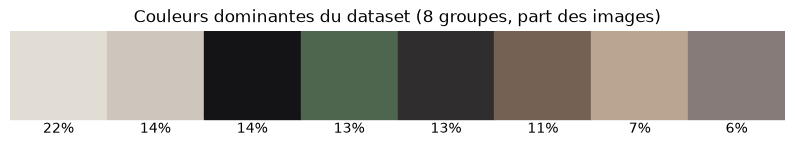

In [13]:
#palette globale des couleurs dominantes
cols = np.array(df_img["dom_color"].tolist())
km = KMeans(n_clusters=8, n_init=5, random_state=0).fit(cols)
counts = np.bincount(km.labels_)
order = np.argsort(-counts)

fig, ax = plt.subplots(figsize=(10, 1.5))
for i, idx in enumerate(order):
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=km.cluster_centers_[idx] / 255))
    ax.text(i + 0.5, -0.15, f"{counts[idx] / len(cols):.0%}", ha="center")
ax.set_xlim(0, 8); ax.set_ylim(-0.3, 1); ax.axis("off")
ax.set_title("Couleurs dominantes du dataset (8 groupes, part des images)")
plt.show()

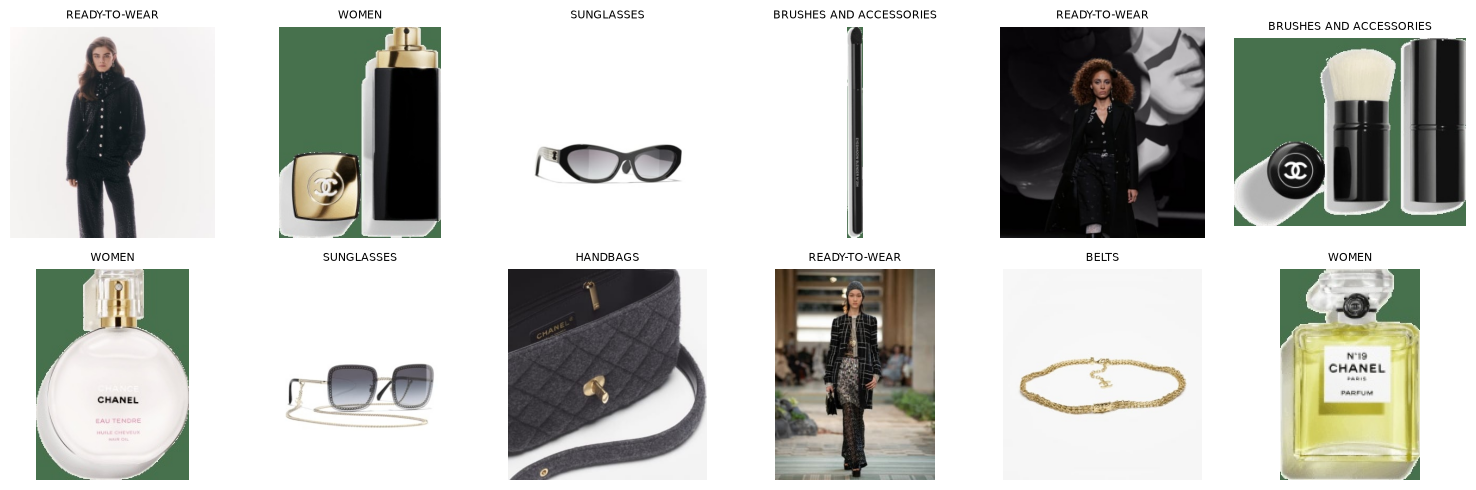

In [15]:
sample = df_img.sample(12, random_state=1)
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r["image_path"]))
    ax.set_title(r["category2_code"], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()